# Program 02: task splits

**What:** split CIFAR-100 into 10 tasks of 10 classes each, and get the train and test loader for any task.

**Why:** continual learning is defined by *what data the model sees when*. `common/data.py` controls that for the whole project; this notebook checks it.

**Understanding note:** in class-incremental learning, one output head covers all classes seen so far, and the model is never told which task a test image came from. That is harder than task-incremental learning, where the task id is given.

**Done when:** each task has 5,000 train and 1,000 test images, and no class appears in two tasks.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Find the project root (the folder that holds common/), whether this notebook
# was opened from the project root or from programs/.
ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

import matplotlib.pyplot as plt
import numpy as np
import torch

from common.data import (CIFAR100_MEAN, CIFAR100_STD, N_TASKS, SplitCIFAR100,
                         get_class_order, task_classes)
from common.utils import RESULTS_DIR, log_run

SEED = 0

## 2. The class order

We shuffle the 100 classes once with a fixed seed, then *rename* every class to its position in that order. After renaming, task t simply holds labels 10t to 10t+9.

So "label 0" means "the first class in our order", not the original CIFAR-100 class 0. `class_order[new_label]` gives back the original id.

In [2]:
order = get_class_order(SEED)
print("first 10 original ids:", order[:10].tolist())
print("same seed, same order again:", np.array_equal(order, get_class_order(SEED)))
print("task 3 holds labels:", task_classes(3))

first 10 original ids: [26, 86, 2, 55, 75, 93, 16, 73, 54, 95]
same seed, same order again: True
task 3 holds labels: [30, 31, 32, 33, 34, 35, 36, 37, 38, 39]


## 3. Load the data
This loads CIFAR-100 once. Every loader after this just picks image indices from it.

In [3]:
data = SplitCIFAR100(seed=SEED)
print("train images:", len(data.train_set), "  test images:", len(data.test_set))

train images: 50000   test images: 10000


## 4. Check every task

For each task: 5,000 train images, 1,000 test images, the right 10 labels, and no label used by an earlier task. `assert` stops with an error if any check fails.

In [4]:
seen_labels = set()
rows = []
for t in range(N_TASKS):
    train_sub, test_sub = data.get_task_subsets(t)

    # Read the labels straight from the stored targets (fast, no image loading).
    train_labels = {data.train_set.targets[i] for i in train_sub.indices}
    test_labels = {data.test_set.targets[i] for i in test_sub.indices}

    assert len(train_sub) == 5000, f"task {t}: {len(train_sub)} train images"
    assert len(test_sub) == 1000, f"task {t}: {len(test_sub)} test images"
    assert train_labels == test_labels == set(task_classes(t)), f"task {t}: wrong labels"
    assert not (train_labels & seen_labels), f"task {t}: a class repeats from an earlier task"
    seen_labels |= train_labels

    names = [data.class_names[c] for c in task_classes(t)]
    rows.append((t, len(train_sub), len(test_sub), names))

assert seen_labels == set(range(100)), "some classes are missing"

print(f"{'task':>4} {'train':>6} {'test':>5}  classes")
for t, n_train, n_test, names in rows:
    print(f"{t:>4} {n_train:>6} {n_test:>5}  {', '.join(names)}")
print("\nAll checks passed: 10 tasks x (5,000 train, 1,000 test), no class in two tasks.")

task  train  test  classes
   0   5000  1000  crab, telephone, baby, otter, skunk, turtle, can, shark, orchid, whale
   1   5000  1000  orange, tulip, snake, bus, beetle, dolphin, clock, cockroach, forest, bicycle
   2   5000  1000  lion, poppy, bear, sea, lobster, motorcycle, bee, worm, sunflower, skyscraper
   3   5000  1000  plain, squirrel, train, road, mushroom, crocodile, caterpillar, palm_tree, porcupine, shrew
   4   5000  1000  aquarium_fish, plate, leopard, lawn_mower, beaver, camel, castle, lamp, kangaroo, bed
   5   5000  1000  trout, pine_tree, apple, fox, cup, mouse, boy, girl, cloud, oak_tree
   6   5000  1000  bowl, elephant, raccoon, pear, spider, tank, flatfish, table, butterfly, tractor
   7   5000  1000  cattle, dinosaur, mountain, wolf, woman, rocket, chair, wardrobe, seal, snail
   8   5000  1000  couch, house, streetcar, man, keyboard, rabbit, pickup_truck, bridge, tiger, rose
   9   5000  1000  television, hamster, chimpanzee, sweet_pepper, bottle, willow_tree, 

## 5. Loader for a single class

Later programs unlearn one class at a time, so we need `get_class_loader(c)`. One class has 500 train and 100 test images.

In [5]:
label = 0
for train, expected in [(True, 500), (False, 100)]:
    loader = data.get_class_loader(label, train=train)
    labels = torch.cat([y for _, y in loader])
    assert len(labels) == expected and (labels == label).all()
    print(f"class {label} ({data.class_names[label]}), {'train' if train else 'test'}: {len(labels)} images  OK")

class 0 (crab), train: 500 images  OK
class 0 (crab), test: 100 images  OK


## 6. One real batch from a task loader
Images should be 3×32×32 and all labels should belong to the task.

In [6]:
train_loader, _ = data.get_task_loaders(3)
images, labels = next(iter(train_loader))
assert images.shape[1:] == (3, 32, 32)
assert set(labels.tolist()) <= set(task_classes(3))
print("batch shape:", tuple(images.shape), "  labels:", sorted(set(labels.tolist())))

batch shape: (32, 3, 32, 32)   labels: [30, 31, 32, 33, 34, 35, 36, 37, 38, 39]


## 7. See all tasks
One example image per class. Rows are tasks, columns are the 10 classes of that task.

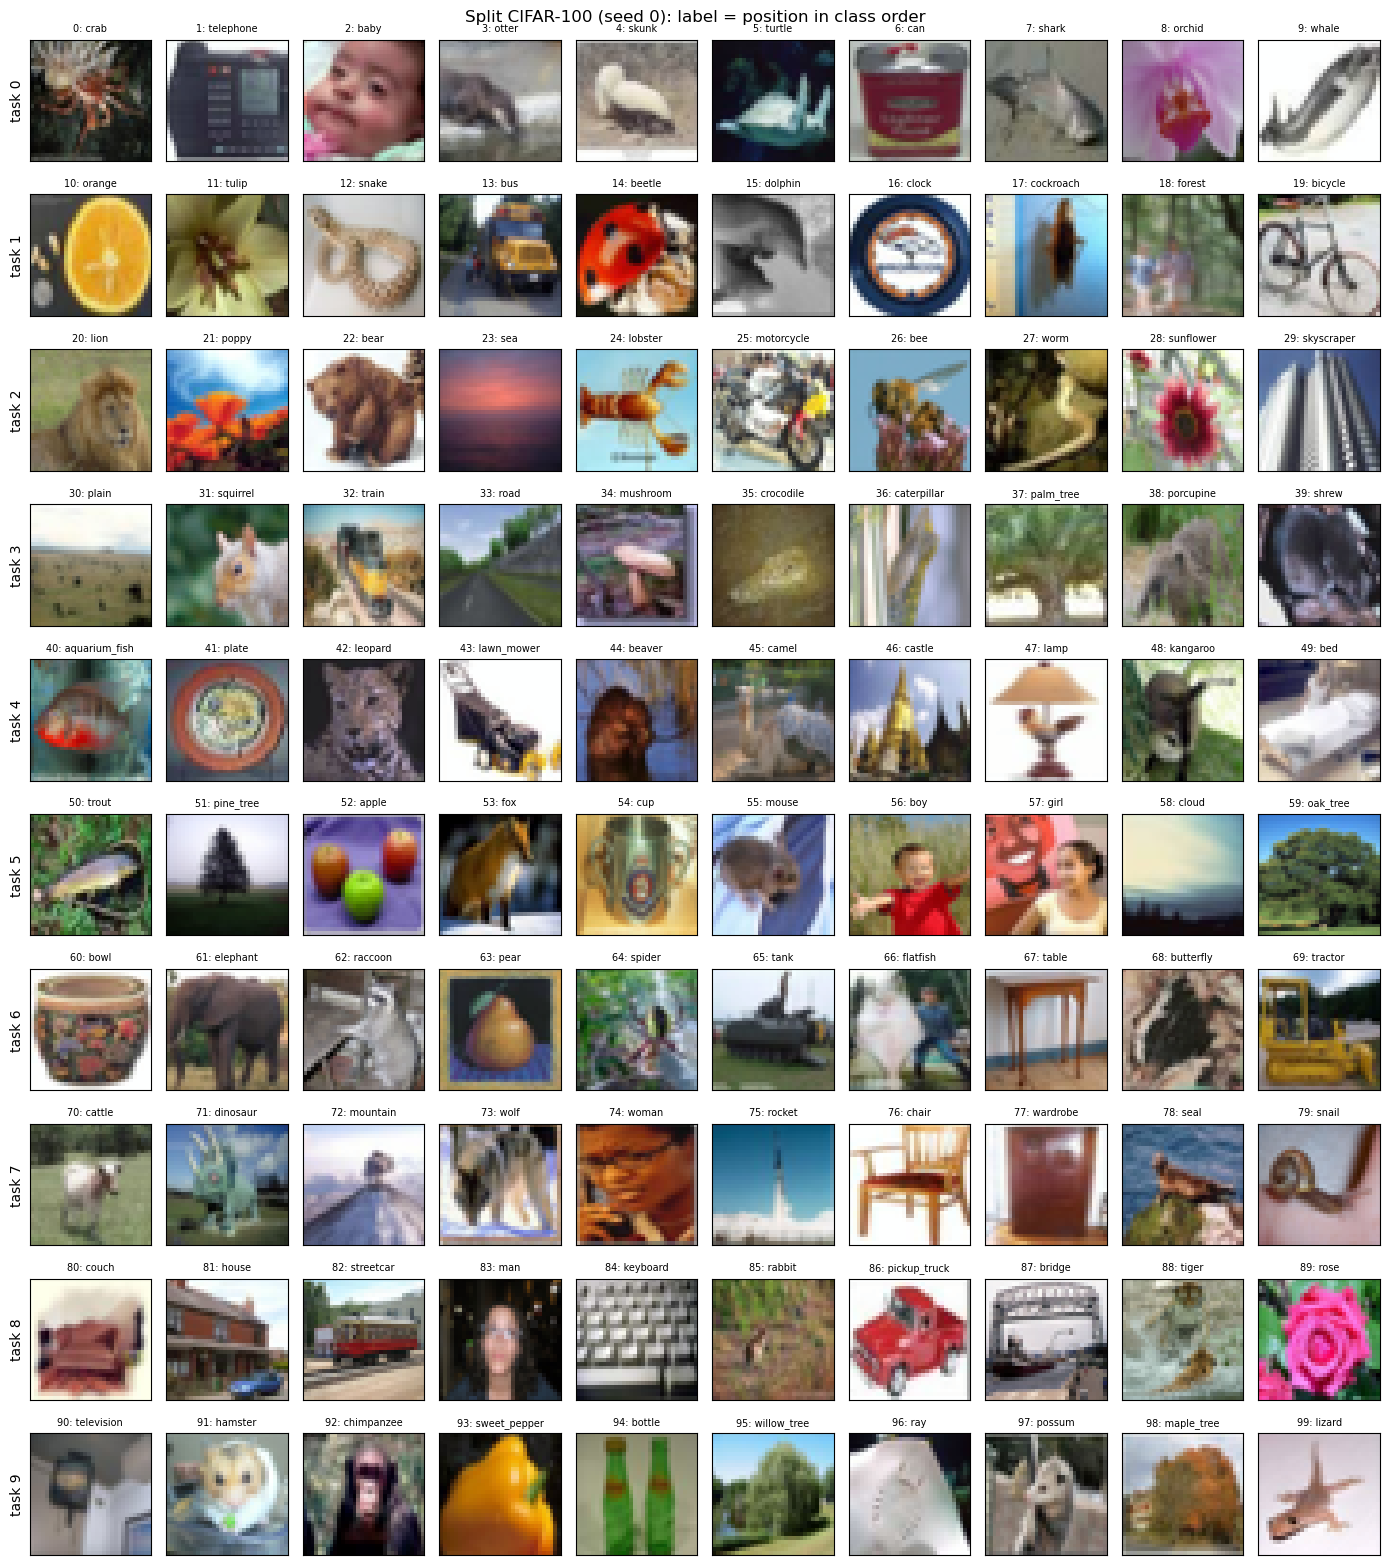

In [7]:
mean, std = np.array(CIFAR100_MEAN), np.array(CIFAR100_STD)
fig, axes = plt.subplots(N_TASKS, 10, figsize=(14, 16))
for t in range(N_TASKS):
    for j, label in enumerate(task_classes(t)):
        idx = data._test_idx[label][0]  # first test image of this class
        img, _ = data.test_set[idx]
        img = (img.permute(1, 2, 0).numpy() * std + mean).clip(0, 1)  # undo normalization
        ax = axes[t, j]
        ax.imshow(img)
        ax.set_xticks([]), ax.set_yticks([])
        ax.set_title(f"{label}: {data.class_names[label]}", fontsize=7)
        if j == 0:
            ax.set_ylabel(f"task {t}", fontsize=10)
fig.suptitle(f"Split CIFAR-100 (seed {SEED}): label = position in class order", fontsize=12)
fig.tight_layout()
RESULTS_DIR.mkdir(exist_ok=True)
fig.savefig(RESULTS_DIR / "02_task_grid.png", dpi=110)
plt.show()

## 8. Log the run

In [8]:
log_run("02_split_dataset", {"seed": SEED},
        {"class_order": data.class_order.tolist(),
         "tasks": {t: names for t, _, _, names in rows}})
print("logged to", RESULTS_DIR / "runs.jsonl")

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*